<a href="https://colab.research.google.com/github/cdokku-tech/MAT422/blob/main/MAT422_Section_3_2_Limits_Derivatives_Taylor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 — Section 3.2: Limits, Derivatives, and Taylor's Theorem

**Student:** Charan Sriraj Dokku

**Course:** MAT 422 — Mathematical Methods in Data Science

**Topics**
1. **3.2.1 Limits and continuity:** the $\varepsilon$–$\delta$ definition, one-sided limits, kinds of discontinuity, limits in several variables, the Extreme Value Theorem
2. **3.2.2 Derivatives:** the difference quotient, finite-difference error, differentiation rules, the Mean Value Theorem, partial derivatives and gradients, directional derivatives, the multivariable chain rule, the Hessian
3. **3.2.3 Taylor's theorem:** Taylor polynomials, the Lagrange remainder bound, order of the error, radius of convergence, the second-order multivariable expansion

**Why this matters in data science.** Training a model means minimizing a loss function. Gradient descent needs **derivatives** (gradients). Newton's method and the analysis of a minimum need **Taylor's theorem** (a quadratic model built from the Hessian). And both only make sense for functions that are **continuous** and smooth enough. This notebook demonstrates each idea with a small example and then checks the claim numerically, so the math is visible in the output.

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from math import factorial
from scipy.optimize import brentq

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
rng = np.random.default_rng(422)   # fixed seed so results are reproducible

---
# Part 1 — Limits and Continuity (3.2.1)

### Definition
We write $\displaystyle\lim_{x\to a} f(x) = L$ if for every $\varepsilon > 0$ there is a $\delta > 0$ such that

$$0 < |x - a| < \delta \;\Longrightarrow\; |f(x) - L| < \varepsilon .$$

In words: we can make $f(x)$ as close to $L$ as we like by taking $x$ close enough to $a$. The value $f(a)$ itself does not matter, or even need to exist.

$f$ is **continuous at $a$** if $\displaystyle\lim_{x\to a} f(x) = f(a)$. It is continuous on a set if it is continuous at every point of the set.

## 1.1 Approaching a limit numerically: $\displaystyle\lim_{x\to 0}\frac{\sin x}{x} = 1$

$\frac{\sin x}{x}$ is undefined at $x=0$, but the limit exists. We evaluate it from **both sides** with shrinking $|x|$, and confirm with SymPy's exact symbolic limit.

In [ ]:
xs = np.array([0.5, 0.1, 0.01, 0.001, 1e-5])
print(f"{'x':>10} | {'sin(x)/x  (x>0)':>18} | {'sin(-x)/(-x)  (x<0)':>20}")
for x in xs:
    print(f"{x:>10.0e} | {np.sin(x)/x:>18.12f} | {np.sin(-x)/(-x):>20.12f}")

x = sp.symbols("x")
print("\nSymPy exact limit:", sp.limit(sp.sin(x)/x, x, 0))

         x |    sin(x)/x  (x>0) |  sin(-x)/(-x)  (x<0)
     5e-01 |     0.958851077208 |       0.958851077208
     1e-01 |     0.998334166468 |       0.998334166468
     1e-02 |     0.999983333417 |       0.999983333417
     1e-03 |     0.999999833333 |       0.999999833333
     1e-05 |     0.999999999983 |       0.999999999983

SymPy exact limit: 1


**Interpretation.** The values agree from the left and the right and approach $1$. The gap $1 - \frac{\sin x}{x}$ shrinks roughly like $x^2/6$, which Taylor's theorem will explain in Part 3. SymPy confirms the exact limit is $1$.

## 1.2 Checking the $\varepsilon$–$\delta$ definition directly

**Linear example.** For $f(x) = 3x + 1$ at $a = 2$ we have $L = 7$, and $|f(x) - 7| = 3|x-2|$. So choosing $\delta = \varepsilon/3$ works.

**Nonlinear example.** For $g(x) = x^2$ at $a = 3$ we have $L = 9$, and $|x^2 - 9| = |x-3|\,|x+3|$. If $|x - 3| < 1$ then $|x+3| < 7$, so choosing $\delta = \min(1, \varepsilon/7)$ works.

We test each proof by sampling many points with $0 < |x-a| < \delta$ and checking that the largest error stays below $\varepsilon$.

In [ ]:
def check_eps_delta(f, a, L, delta_rule, eps_list, n=100_000):
    print(f"{'epsilon':>9} | {'delta':>10} | {'max |f(x)-L|':>14} | holds?")
    for eps in eps_list:
        d = delta_rule(eps)
        xs = a + rng.uniform(-d, d, n)
        xs = xs[xs != a]                     # 0 < |x - a| < delta
        worst = np.max(np.abs(f(xs) - L))
        print(f"{eps:>9.0e} | {d:>10.3e} | {worst:>14.3e} | {worst < eps}")

print("f(x) = 3x + 1,  a = 2,  L = 7,  delta = eps/3")
check_eps_delta(lambda t: 3*t + 1, 2, 7, lambda e: e/3, [1, 0.1, 0.01, 0.001])

print("\ng(x) = x^2,  a = 3,  L = 9,  delta = min(1, eps/7)")
check_eps_delta(lambda t: t**2, 3, 9, lambda e: min(1, e/7), [5, 0.5, 0.05, 0.005])

f(x) = 3x + 1,  a = 2,  L = 7,  delta = eps/3
  epsilon |      delta |   max |f(x)-L| | holds?
    1e+00 |  3.333e-01 |      1.000e+00 | True
    1e-01 |  3.333e-02 |      1.000e-01 | True
    1e-02 |  3.333e-03 |      1.000e-02 | True
    1e-03 |  3.333e-04 |      1.000e-03 | True

g(x) = x^2,  a = 3,  L = 9,  delta = min(1, eps/7)
  epsilon |      delta |   max |f(x)-L| | holds?
    5e+00 |  7.143e-01 |      4.796e+00 | True
    5e-01 |  7.143e-02 |      4.336e-01 | True
    5e-02 |  7.143e-03 |      4.291e-02 | True
    5e-03 |  7.143e-04 |      4.286e-03 | True


**Interpretation.** For every $\varepsilon$ tested, the worst sampled error is below $\varepsilon$, as the algebra predicted. Sampling cannot *prove* a limit, since it checks only finitely many points. It does catch a wrong choice of $\delta$. Try `delta = 2*eps` in the first example and watch it fail.

## 1.3 One-sided limits and the three kinds of discontinuity

The limit $\lim_{x\to a} f(x)$ exists exactly when both one-sided limits $\lim_{x\to a^-}$ and $\lim_{x\to a^+}$ exist and are equal. A function can fail to be continuous at $a$ in three classic ways:

| Type | Example at $x=1$ | What goes wrong |
|---|---|---|
| **Removable** | $\dfrac{x^2-1}{x-1}$ | the limit exists ($=2$), but $f(1)$ is undefined |
| **Jump** | $x^2$ for $x<1$, and $x+1$ for $x \ge 1$ | the one-sided limits differ ($1 \ne 2$) |
| **Infinite** | $\dfrac{1}{x-1}$ | the function is unbounded near $1$ |

removable: left limit =     2, right limit =     2, two-sided limit exists: True
     jump: left limit =     1, right limit =     2, two-sided limit exists: False
 infinite: left limit =   -oo, right limit =    oo, two-sided limit exists: False


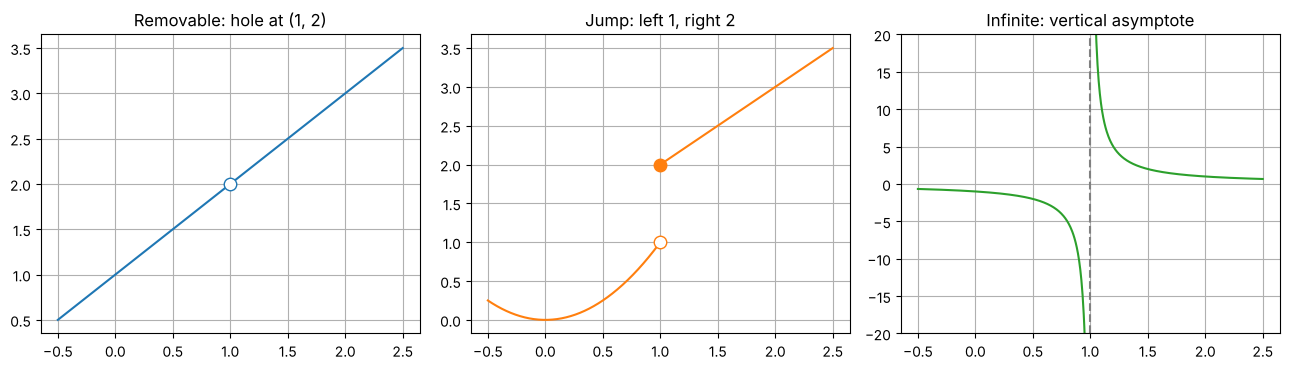

In [ ]:
x = sp.symbols("x")
# (left-side formula, right-side formula) near x = 1
cases = {
    "removable": ((x**2 - 1)/(x - 1), (x**2 - 1)/(x - 1)),
    "jump":      (x**2,               x + 1),
    "infinite":  (1/(x - 1),          1/(x - 1)),
}
for name, (left_expr, right_expr) in cases.items():
    left  = sp.limit(left_expr,  x, 1, dir="-")
    right = sp.limit(right_expr, x, 1, dir="+")
    print(f"{name:>9}: left limit = {str(left):>5}, right limit = {str(right):>5}, "
          f"two-sided limit exists: {left == right and left.is_finite}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
t = np.linspace(-0.5, 2.5, 600)

t1 = t[np.abs(t - 1) > 1e-9]
axes[0].plot(t1, (t1**2 - 1)/(t1 - 1))
axes[0].plot(1, 2, "o", mfc="white", mec="C0", ms=9)
axes[0].set_title("Removable: hole at (1, 2)")

tl, tr = t[t < 1], t[t >= 1]
axes[1].plot(tl, tl**2, "C1"); axes[1].plot(tr, tr + 1, "C1")
axes[1].plot(1, 1, "o", mfc="white", mec="C1", ms=9); axes[1].plot(1, 2, "o", c="C1", ms=9)
axes[1].set_title("Jump: left 1, right 2")

for seg in (t[t < 0.97], t[t > 1.03]):
    axes[2].plot(seg, 1/(seg - 1), "C2")
axes[2].axvline(1, ls="--", c="gray"); axes[2].set_ylim(-20, 20)
axes[2].set_title("Infinite: vertical asymptote")
plt.tight_layout(); plt.show()

**Interpretation.** Only the removable discontinuity has a two-sided limit. Defining $f(1) = 2$ "fills the hole" and makes that function continuous. The jump cannot be repaired, because the two sides disagree. In data science, step-like functions such as a hard 0/1 threshold classifier have jumps like this. That is why we usually replace them with continuous surrogates such as the sigmoid.

## 1.4 Limits in several variables: the path matters

In $\mathbb{R}^2$ the point $(x,y)$ can approach $(0,0)$ along infinitely many paths. The limit exists only if **every** path gives the same value. Compare

$$f(x,y) = \frac{xy}{x^2+y^2}, \qquad g(x,y) = \frac{x^2 y}{x^2+y^2}.$$

Along the line $y = mx$, $f$ is constant: $f = \frac{m}{1+m^2}$, so different slopes give different values and $\lim f$ does **not** exist. For $g$, the inequality $x^2 \le x^2+y^2$ gives $|g| \le |y| \to 0$, so $\lim g = 0$ by the squeeze theorem.

              path |  f near (0,0) |  g near (0,0)
            y = 0x |      0.000000 |      0.00e+00
          y = 0.5x |      0.400000 |      3.58e-07
            y = 1x |      0.500000 |      3.54e-07
            y = 2x |      0.400000 |      1.79e-07
           y = -1x |     -0.500000 |     -3.54e-07
           y = x^2 |      0.000001 |      1.00e-12


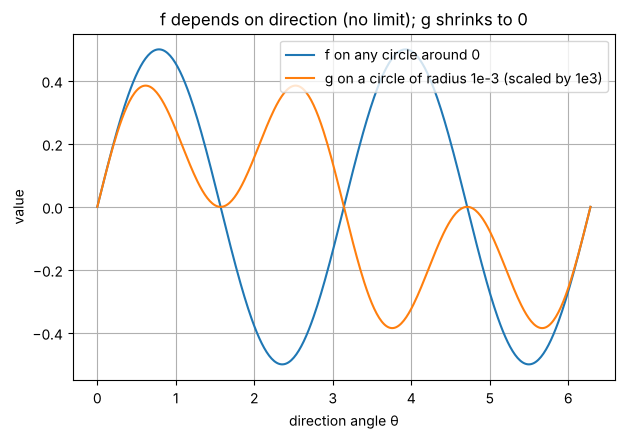

In [ ]:
f = lambda x, y: x*y/(x**2 + y**2)
g = lambda x, y: x**2*y/(x**2 + y**2)

r = 1e-6   # a point very close to the origin
print(f"{'path':>18} | {'f near (0,0)':>13} | {'g near (0,0)':>13}")
for slope in [0, 0.5, 1, 2, -1]:
    px, py = r/np.sqrt(1 + slope**2), slope*r/np.sqrt(1 + slope**2)
    print(f"{'y = ' + str(slope) + 'x':>18} | {f(px, py):>13.6f} | {g(px, py):>13.2e}")
px, py = r, r**2                                   # a curved path y = x^2
print(f"{'y = x^2':>18} | {f(px, py):>13.6f} | {g(px, py):>13.2e}")

theta = np.linspace(0, 2*np.pi, 400)
plt.plot(theta, f(np.cos(theta), np.sin(theta)), label="f on any circle around 0")
plt.plot(theta, g(1e-3*np.cos(theta), 1e-3*np.sin(theta))*1e3,
         label="g on a circle of radius 1e-3 (scaled by 1e3)")
plt.xlabel("direction angle θ"); plt.ylabel("value")
plt.title("f depends on direction (no limit); g shrinks to 0")
plt.legend(); plt.show()

**Interpretation.** Near the origin, $f$ takes every value between $-\tfrac12$ and $\tfrac12$ depending on the direction of approach, so no single limit exists. $g$ is tiny in every direction and shrinks with the radius, so $\lim g = 0$. Checking a few straight-line paths can **disprove** a multivariable limit, but it can never prove one. Proving it needs a bound like $|g| \le |y|$.

## 1.5 Continuity in action: the Extreme Value Theorem

**Theorem.** If $f$ is continuous on a **closed and bounded** set (for example $[a,b]$), then $f$ attains a maximum and a minimum there.

This is why minimizing a continuous loss over a compact parameter set is guaranteed to have a solution. Both hypotheses are needed:
* $f(x) = x e^{-x}$ on $[0, 3]$ is continuous on a closed interval, so its maximum is attained (at $x=1$, value $1/e$).
* $h(x) = 1/x$ on $(0, 1]$ is continuous, but the interval is not closed. It has no maximum, because it grows without bound as $x \to 0^+$.

In [ ]:
grid = np.linspace(0, 3, 300_001)
fx = grid*np.exp(-grid)
i = np.argmax(fx)
print(f"x e^(-x) on [0,3]: max ≈ {fx[i]:.8f} at x ≈ {grid[i]:.5f}   (exact 1/e = {np.exp(-1):.8f} at x = 1)")

print("\n1/x on (0,1]: largest value found on finer and finer grids")
for k in range(1, 7):
    pts = np.linspace(10.0**-k, 1, 1000)
    print(f"  grid starting at 1e-{k}:  max = {np.max(1/pts):>10.1f}")

x e^(-x) on [0,3]: max ≈ 0.36787944 at x ≈ 1.00000   (exact 1/e = 0.36787944 at x = 1)

1/x on (0,1]: largest value found on finer and finer grids
  grid starting at 1e-1:  max =       10.0
  grid starting at 1e-2:  max =      100.0
  grid starting at 1e-3:  max =     1000.0
  grid starting at 1e-4:  max =    10000.0
  grid starting at 1e-5:  max =   100000.0
  grid starting at 1e-6:  max =  1000000.0


**Interpretation.** On the closed interval the maximum is found and matches the exact value $1/e$. On $(0,1]$ the "maximum" keeps growing as the grid gets closer to $0$, so no maximum exists. The Extreme Value Theorem does not apply there, because its hypothesis fails.

---
# Part 2 — Derivatives (3.2.2)

### Definition
$$f'(a) = \lim_{h \to 0}\frac{f(a+h) - f(a)}{h}.$$
The derivative is a *limit of slopes of secant lines*, so it is a direct application of Part 1. If $f$ is differentiable at $a$, then it is also continuous at $a$. The converse is false.

## 2.1 The difference quotient, and how accurate finite differences are

Computers cannot take $h \to 0$, so we use finite differences:
* **forward:** $\dfrac{f(a+h)-f(a)}{h}$, with error $O(h)$
* **central:** $\dfrac{f(a+h)-f(a-h)}{2h}$, with error $O(h^2)$

These error orders come straight from Taylor's theorem (Part 3). A second effect also matters. When $h$ is very small, floating-point **round-off** error, of size about $10^{-16}/h$, takes over. We test both formulas on $f(x) = e^{x}\sin x$ at $a=1$, where the exact derivative is $f'(x) = e^x(\sin x + \cos x)$.

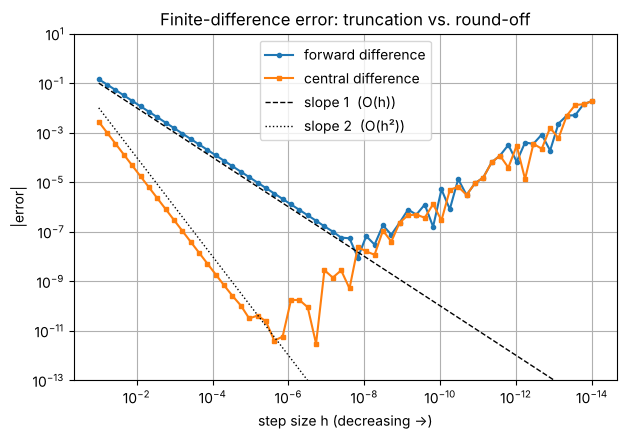

fitted slope, forward: 0.998
fitted slope, central: 2.0
best forward h ≈ 1.5e-08, best central h ≈ 1.9e-07


In [ ]:
f  = lambda x: np.exp(x)*np.sin(x)
df = lambda x: np.exp(x)*(np.sin(x) + np.cos(x))
a = 1.0
hs = np.logspace(-1, -14, 60)

fwd = (f(a + hs) - f(a))/hs
ctr = (f(a + hs) - f(a - hs))/(2*hs)
err_fwd = np.abs(fwd - df(a))
err_ctr = np.abs(ctr - df(a))

plt.loglog(hs, err_fwd, "o-", ms=3, label="forward difference")
plt.loglog(hs, err_ctr, "s-", ms=3, label="central difference")
plt.loglog(hs, hs, "k--", lw=1, label="slope 1  (O(h))")
plt.loglog(hs, hs**2, "k:", lw=1, label="slope 2  (O(h²))")
plt.gca().invert_xaxis(); plt.ylim(1e-13, 10)
plt.xlabel("step size h (decreasing →)"); plt.ylabel("|error|")
plt.title("Finite-difference error: truncation vs. round-off")
plt.legend(); plt.show()

big = hs > 1e-4   # region where truncation error dominates
print("fitted slope, forward:", np.polyfit(np.log(hs[big]), np.log(err_fwd[big]), 1)[0].round(3))
print("fitted slope, central:", np.polyfit(np.log(hs[big]), np.log(err_ctr[big]), 1)[0].round(3))
print(f"best forward h ≈ {hs[np.argmin(err_fwd)]:.1e}, best central h ≈ {hs[np.argmin(err_ctr)]:.1e}")

**Interpretation.** For large $h$ the measured slopes are about $1$ and $2$, as theory predicts. Below an optimal $h$ (printed above), round-off makes the error *grow* again. Theory puts the optimum near $\sqrt{10^{-16}} = 10^{-8}$ for the forward formula and near $10^{-16/3}\approx 10^{-5}$ for the central one. The measured optimum for the central formula is a bit noisy, because round-off error is random. The lesson: the limit in the definition is exact, but in floating point we cannot simply take $h$ as small as possible.

## 2.2 Continuous but not differentiable: ReLU

$\mathrm{ReLU}(x) = \max(0, x)$ is the most common activation function in neural networks. It is continuous everywhere, but at $x = 0$ its one-sided difference quotients disagree:
$$\lim_{h\to0^-}\frac{\mathrm{ReLU}(h)-0}{h} = 0, \qquad \lim_{h\to0^+}\frac{\mathrm{ReLU}(h)-0}{h} = 1.$$
So $\mathrm{ReLU}'(0)$ does not exist. In practice, libraries simply choose a value there (usually $0$).

In [ ]:
relu = lambda x: np.maximum(0, x)
for h in [1e-1, 1e-3, 1e-6]:
    left  = (relu(-h) - relu(0.0))/(-h) + 0.0   # + 0.0 turns -0.0 into 0.0
    right = (relu(h) - relu(0))/h
    print(f"h = {h:.0e}:  left quotient = {left:.1f},  right quotient = {right:.1f}")
print("ReLU continuous at 0?", relu(-1e-12), relu(0.0), relu(1e-12), "→ all ≈ 0, yes")

h = 1e-01:  left quotient = 0.0,  right quotient = 1.0
h = 1e-03:  left quotient = 0.0,  right quotient = 1.0
h = 1e-06:  left quotient = 0.0,  right quotient = 1.0
ReLU continuous at 0? 0.0 0.0 1e-12 → all ≈ 0, yes


**Interpretation.** The left quotients stay at $0$ and the right ones stay at $1$, for every $h$. So the derivative limit does not exist, even though ReLU is continuous at 0. This is the counterexample to "continuous ⇒ differentiable."

## 2.3 Differentiation rules, verified symbolically: the sigmoid

The **sigmoid** $\sigma(z) = \dfrac{1}{1+e^{-z}}$ is used in logistic regression (Section 3.4). The chain and quotient rules give the identity
$$\sigma'(z) = \sigma(z)\,\bigl(1-\sigma(z)\bigr).$$
We check this with SymPy, and then numerically with a central difference.

In [ ]:
z = sp.symbols("z")
sigma = 1/(1 + sp.exp(-z))
d_sigma = sp.diff(sigma, z)
print("SymPy derivative:      ", d_sigma)
print("σ(1-σ) - σ' simplifies to:", sp.simplify(sigma*(1 - sigma) - d_sigma))

sig = sp.lambdify(z, sigma, "numpy")
zs = np.linspace(-6, 6, 7)
h = 1e-5
numeric = (sig(zs + h) - sig(zs - h))/(2*h)
identity = sig(zs)*(1 - sig(zs))
print("\nz:              ", zs)
print("numeric σ'(z):  ", numeric)
print("σ(z)(1-σ(z)):   ", identity)
print("max difference: ", np.max(np.abs(numeric - identity)))

SymPy derivative:       exp(-z)/(1 + exp(-z))**2
σ(1-σ) - σ' simplifies to: 0

z:               [-6. -4. -2.  0.  2.  4.  6.]
numeric σ'(z):   [0.002467 0.017663 0.104994 0.25     0.104994 0.017663 0.002467]
σ(z)(1-σ(z)):    [0.002467 0.017663 0.104994 0.25     0.104994 0.017663 0.002467]
max difference:  6.688899434337259e-12


**Interpretation.** The symbolic difference simplifies to exactly $0$, and the numeric derivative matches $\sigma(1-\sigma)$ to about $10^{-11}$. The derivative peaks at $z=0$ (value $0.25$) and vanishes for large $|z|$. This "vanishing gradient" is one reason sigmoids can make deep networks slow to train.

## 2.4 Mean Value Theorem

**Theorem.** If $f$ is continuous on $[a,b]$ and differentiable on $(a,b)$, then some $c \in (a,b)$ satisfies
$$f'(c) = \frac{f(b)-f(a)}{b-a}.$$
At some point, the instantaneous slope equals the average slope.

**Example.** $f(x) = x^3 - 2x + 1$ on $[0, 2]$. The average slope is $\frac{5-1}{2} = 2$. Solving $3c^2 - 2 = 2$ gives $c = 2/\sqrt3 \approx 1.1547$. We find $c$ numerically with a root finder and draw the secant and tangent lines.

secant slope = 2.0,  c = 1.154701,  exact 2/sqrt(3) = 1.154701,  f'(c) = 2.000000


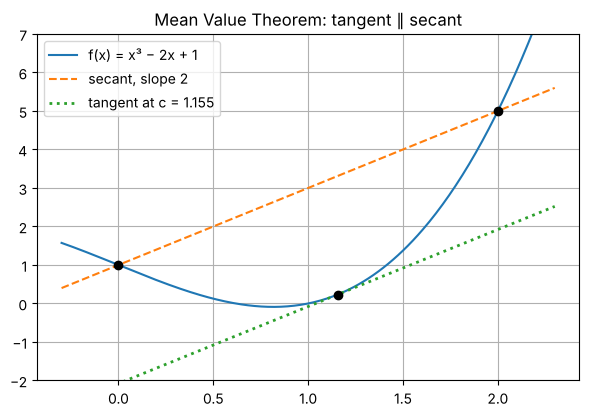

In [ ]:
f  = lambda x: x**3 - 2*x + 1
df = lambda x: 3*x**2 - 2
a, b = 0.0, 2.0
secant_slope = (f(b) - f(a))/(b - a)
c = brentq(lambda t: df(t) - secant_slope, a + 1e-9, b)   # solve f'(c) = secant slope
print(f"secant slope = {secant_slope},  c = {c:.6f},  exact 2/sqrt(3) = {2/np.sqrt(3):.6f},  f'(c) = {df(c):.6f}")

t = np.linspace(-0.3, 2.3, 300)
plt.plot(t, f(t), label="f(x) = x³ − 2x + 1")
plt.plot(t, f(a) + secant_slope*(t - a), "--", label=f"secant, slope {secant_slope:.0f}")
plt.plot(t, f(c) + df(c)*(t - c), ":", lw=2, label=f"tangent at c = {c:.3f}")
plt.plot([a, b, c], [f(a), f(b), f(c)], "ko")
plt.ylim(-2, 7); plt.legend(); plt.title("Mean Value Theorem: tangent ∥ secant"); plt.show()

**Interpretation.** The tangent at $c \approx 1.1547$ is exactly parallel to the secant through the endpoints. The MVT is the key step in proving Taylor's theorem. It also underlies "Lipschitz" bounds of the form $|f(x)-f(y)| \le \max|f'|\cdot|x-y|$, which appear in convergence proofs for gradient descent.

## 2.5 Partial derivatives and the gradient

For $f:\mathbb{R}^d\to\mathbb{R}$, the partial derivative $\partial f/\partial x_i$ differentiates in $x_i$ while holding the other variables fixed. The **gradient** collects all of them:
$$\nabla f(\mathbf{x}) = \left(\frac{\partial f}{\partial x_1},\dots,\frac{\partial f}{\partial x_d}\right)^{\!T}.$$

We use the non-quadratic function
$$f(x,y) = x^2 + 2y^2 + \sin(xy)$$
for the rest of the notebook. We get its gradient symbolically, and check it with central differences at a test point.

In [ ]:
X, Y = sp.symbols("x y")
F = X**2 + 2*Y**2 + sp.sin(X*Y)
grad_F = [sp.diff(F, v) for v in (X, Y)]
print("∂f/∂x =", grad_F[0])
print("∂f/∂y =", grad_F[1])

f_num    = sp.lambdify((X, Y), F, "numpy")
grad_num = sp.lambdify((X, Y), grad_F, "numpy")

def fd_gradient(fun, p, h=1e-6):
    p = np.asarray(p, float); g = np.zeros_like(p)
    for i in range(len(p)):
        e = np.zeros_like(p); e[i] = h
        g[i] = (fun(*(p + e)) - fun(*(p - e)))/(2*h)
    return g

p0 = np.array([1.0, 0.5])
print("\nexact gradient at", p0, ":", np.array(grad_num(*p0)))
print("finite-diff gradient     :", fd_gradient(f_num, p0))

∂f/∂x = 2*x + y*cos(x*y)
∂f/∂y = x*cos(x*y) + 4*y

exact gradient at [1.  0.5] : [2.438791 2.877583]
finite-diff gradient     : [2.438791 2.877583]


### The gradient is perpendicular to level curves

The gradient points in the direction of steepest increase, and it is orthogonal to the level curve $f = c$ through each point. Gradient descent moves in the direction $-\nabla f$.

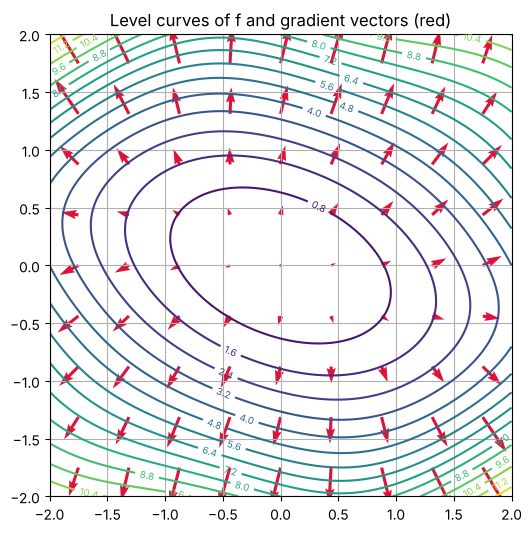

In [ ]:
gx, gy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
plt.figure(figsize=(6, 6))
cs = plt.contour(gx, gy, f_num(gx, gy), levels=15, cmap="viridis")
plt.clabel(cs, fontsize=7)
qx, qy = np.meshgrid(np.linspace(-1.75, 1.75, 9), np.linspace(-1.75, 1.75, 9))
U, V = grad_num(qx, qy)
plt.quiver(qx, qy, U, V, color="crimson", angles="xy")
plt.gca().set_aspect("equal")
plt.title("Level curves of f and gradient vectors (red)"); plt.show()

**Interpretation.** The symbolic and finite-difference gradients agree to about 10 digits. In the plot, every red arrow crosses its level curve at a right angle and points "uphill." This is exactly the geometric picture behind gradient descent (Section 3.3).

## 2.6 Directional derivatives

The rate of change of $f$ at $\mathbf{x}$ in the direction of a unit vector $\mathbf{u}$ is
$$D_{\mathbf u} f(\mathbf x) = \lim_{t\to0}\frac{f(\mathbf x + t\mathbf u)-f(\mathbf x)}{t} = \nabla f(\mathbf x)^T\mathbf u .$$
By Cauchy–Schwarz, $|D_{\mathbf u}f| \le \|\nabla f\|$, with equality when $\mathbf u = \nabla f/\|\nabla f\|$. So the gradient really is the steepest direction.

max |limit-quotient − ∇f·u| over all directions: 1.87e-06
steepest direction angle = 50.0°, gradient angle = 49.7°
max directional derivative = 3.771981,  ||∇f|| = 3.772027


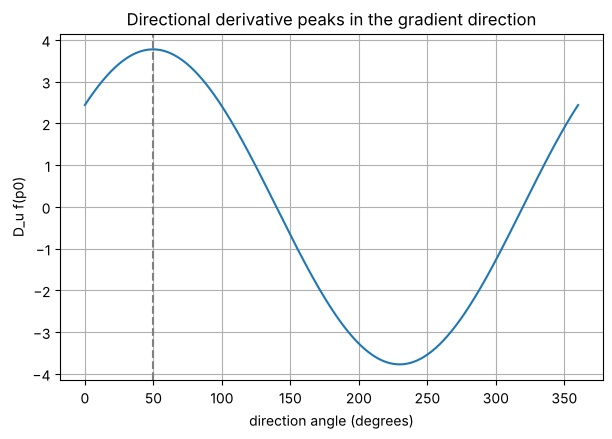

In [ ]:
g0 = np.array(grad_num(*p0))
angles = np.linspace(0, 2*np.pi, 361)
t = 1e-6
D_limit   = np.array([(f_num(*(p0 + t*np.array([np.cos(a), np.sin(a)]))) - f_num(*p0))/t for a in angles])
D_formula = g0[0]*np.cos(angles) + g0[1]*np.sin(angles)

print("max |limit-quotient − ∇f·u| over all directions:", np.max(np.abs(D_limit - D_formula)).round(8))
best = angles[np.argmax(D_formula)]
print(f"steepest direction angle = {np.degrees(best):.1f}°, gradient angle = {np.degrees(np.arctan2(g0[1], g0[0])):.1f}°")
print(f"max directional derivative = {D_formula.max():.6f},  ||∇f|| = {np.linalg.norm(g0):.6f}")

plt.plot(np.degrees(angles), D_formula)
plt.axvline(np.degrees(best), ls="--", c="gray")
plt.xlabel("direction angle (degrees)"); plt.ylabel("D_u f(p0)")
plt.title("Directional derivative peaks in the gradient direction"); plt.show()

**Interpretation.** The limit definition and the formula $\nabla f^T\mathbf u$ agree in all 361 directions. The largest directional derivative matches $\|\nabla f\|$, and it occurs at the gradient's angle. Both agree up to the 1° spacing of the direction grid.

## 2.7 The multivariable chain rule

If $\mathbf x(t)$ is a differentiable path, then
$$\frac{d}{dt} f(\mathbf x(t)) = \nabla f(\mathbf x(t))^T\,\mathbf x'(t).$$
This rule is the mathematical core of **backpropagation** in neural networks (Section 3.7).

**Example.** On the path $\mathbf x(t) = (\cos t,\; t^2)$, we compare a direct symbolic derivative of $f(\cos t, t^2)$ with the chain-rule formula.

In [ ]:
T = sp.symbols("t")
path = (sp.cos(T), T**2)
direct = sp.diff(F.subs({X: path[0], Y: path[1]}), T)
chain  = sum(sp.diff(F, v).subs({X: path[0], Y: path[1]})*sp.diff(comp, T)
             for v, comp in zip((X, Y), path))
print("direct − chain rule simplifies to:", sp.simplify(direct - chain))

for tv in [0.0, 0.7, 1.5]:
    print(f"t = {tv}:  direct = {float(direct.subs(T, tv)):.10f},  chain rule = {float(chain.subs(T, tv)):.10f}")

direct − chain rule simplifies to: 0
t = 0.0:  direct = 0.0000000000,  chain rule = 0.0000000000
t = 0.7:  direct = 2.4612509650,  chain rule = 2.4612509650
t = 1.5:  direct = 24.8524123131,  chain rule = 24.8524123131


**Interpretation.** The two expressions are symbolically identical, and they agree at sample values of $t$. Backpropagation applies this rule repeatedly, layer by layer, to get the gradient of a loss with respect to every weight.

## 2.8 Second derivatives: the Hessian

The **Hessian** is the matrix of second partial derivatives, $\mathbf H_f(\mathbf x)_{ij} = \dfrac{\partial^2 f}{\partial x_i\,\partial x_j}$. When the second partials are continuous, the mixed partials are equal (**Clairaut / Schwarz theorem**), so $\mathbf H$ is symmetric. Its eigenvalues describe the local curvature. If all of them are positive at a critical point, that point is a local minimum.

In [ ]:
H = sp.hessian(F, (X, Y))
print("Hessian of f:"); sp.pprint(H)
print("\nmixed partials equal (Clairaut)?", sp.simplify(H[0, 1] - H[1, 0]) == 0)

H_num = sp.lambdify((X, Y), H, "numpy")
def fd_hessian(fun, p, h=1e-4):
    p = np.asarray(p, float); n = len(p); Hm = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei = np.zeros(n); ej = np.zeros(n); ei[i] = h; ej[j] = h
            Hm[i, j] = (fun(*(p+ei+ej)) - fun(*(p+ei-ej)) - fun(*(p-ei+ej)) + fun(*(p-ei-ej)))/(4*h*h)
    return Hm

print("\nexact Hessian at p0:\n", np.array(H_num(*p0), float))
print("finite-difference Hessian at p0:\n", fd_hessian(f_num, p0))
print("eigenvalues at the origin:", np.linalg.eigvalsh(np.array(H_num(0, 0), float)), "→ both > 0, so (0,0) is a local min")

Hessian of f:
⎡      2                                           ⎤
⎢   - y ⋅sin(x⋅y) + 2      -x⋅y⋅sin(x⋅y) + cos(x⋅y)⎥
⎢                                                  ⎥
⎢                                2                 ⎥
⎣-x⋅y⋅sin(x⋅y) + cos(x⋅y)     - x ⋅sin(x⋅y) + 4    ⎦

mixed partials equal (Clairaut)? True

exact Hessian at p0:
 [[1.880144 0.63787 ]
 [0.63787  3.520574]]
finite-difference Hessian at p0:
 [[1.880144 0.63787 ]
 [0.63787  3.520574]]
eigenvalues at the origin: [1.585786 4.414214] → both > 0, so (0,0) is a local min


### A useful matrix identity: $\nabla(\mathbf x^T A\mathbf x) = (A + A^T)\mathbf x$

Quadratic forms appear everywhere: least squares, covariance, and local models of a loss. For a quadratic form $q(\mathbf x) = \mathbf x^T A\mathbf x$, the gradient is $(A + A^T)\mathbf x$ and the Hessian is $A + A^T$. (The course *Calculus* folder has a reading on this derivation.) We check the gradient formula with a random non-symmetric $A$.

In [ ]:
A = rng.normal(size=(3, 3))           # not symmetric
xv = rng.normal(size=3)
q = lambda *v: np.array(v) @ A @ np.array(v)
print("finite-diff gradient:", fd_gradient(q, xv))
print("(A + Aᵀ)x           :", (A + A.T) @ xv)
print("finite-diff Hessian ≈ A + Aᵀ ?", np.allclose(fd_hessian(q, xv), A + A.T, atol=1e-5))

finite-diff gradient: [-4.41053  -2.589045 -2.827319]
(A + Aᵀ)x           : [-4.41053  -2.589045 -2.827319]
finite-diff Hessian ≈ A + Aᵀ ? True


**Interpretation.** The symbolic Hessian is symmetric, as Clairaut's theorem predicts, and the finite-difference version matches it. Both Hessian eigenvalues at the origin are positive, so $f$ curves upward in every direction there and $(0,0)$ is a local minimum. For a non-symmetric $A$, the gradient of $\mathbf x^TA\mathbf x$ is $(A+A^T)\mathbf x$, **not** $2A\mathbf x$. The shortcut $2A\mathbf x$ is only correct when $A$ is symmetric.

---
# Part 3 — Taylor's Theorem (3.2.3)

### Statement (single variable, Lagrange form)
If $f$ has $n+1$ continuous derivatives near $a$, then
$$f(x) = \underbrace{\sum_{k=0}^{n}\frac{f^{(k)}(a)}{k!}(x-a)^k}_{P_n(x)\ \text{(Taylor polynomial)}} \;+\; \underbrace{\frac{f^{(n+1)}(\xi)}{(n+1)!}(x-a)^{n+1}}_{R_n(x)\ \text{(remainder)}}$$
for some $\xi$ between $a$ and $x$. Two consequences:
* **Error bound:** if $|f^{(n+1)}| \le M$ on the interval, then $|R_n(x)| \le \dfrac{M\,|x-a|^{n+1}}{(n+1)!}$.
* **Error order:** $R_n(x) = O(|x-a|^{n+1})$ as $x \to a$.

For $n = 0$ this is exactly the Mean Value Theorem from §2.4.

## 3.1 Taylor polynomials converge to the function

We build $P_n$ for $f(x) = \cos x$ around $a = 0$. Only even powers appear: $1 - \frac{x^2}{2!} + \frac{x^4}{4!} - \cdots$. The code computes the coefficients with SymPy, so any function can be swapped in.

P_6(x) = -x**6/720 + x**4/24 - x**2/2 + 1


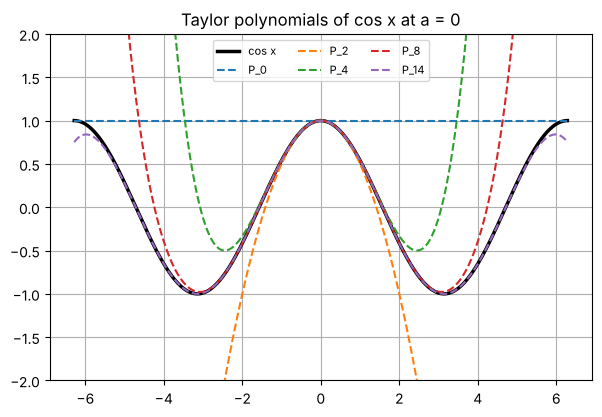

In [ ]:
def taylor_poly(expr, var, a, n):
    return sum(sp.diff(expr, var, k).subs(var, a)/factorial(k)*(var - a)**k for k in range(n + 1))

x = sp.symbols("x")
expr = sp.cos(x)
print("P_6(x) =", sp.expand(taylor_poly(expr, x, 0, 6)))

t = np.linspace(-2*np.pi, 2*np.pi, 500)
plt.plot(t, np.cos(t), "k", lw=2.5, label="cos x")
for n in [0, 2, 4, 8, 14]:
    Pn = sp.lambdify(x, taylor_poly(expr, x, 0, n), "numpy")
    plt.plot(t, Pn(t)*np.ones_like(t), "--", label=f"P_{n}")
plt.ylim(-2, 2); plt.legend(ncol=3, fontsize=8)
plt.title("Taylor polynomials of cos x at a = 0"); plt.show()

**Interpretation.** Each extra term makes the polynomial hug $\cos x$ over a wider interval. Close to $a=0$ even $P_2$ is excellent, while far away we need high degree. A Taylor polynomial is a **local** approximation.

## 3.2 The Lagrange remainder bound is a guarantee

For $f(x) = e^x$ at $a=0$, every derivative is $e^x$. On $[0, 1]$ this is at most $e < 3$, so $M = 3$ works and
$$|e - P_n(1)| \le \frac{3}{(n+1)!}.$$
We check that the actual error is always below this bound, and use it to decide in advance how many terms guarantee 10-digit accuracy for the number $e$.

In [ ]:
print(f"{'n':>3} | {'P_n(1)':>16} | {'actual error':>13} | {'bound 3/(n+1)!':>15} | within bound?")
for n in range(1, 15):
    Pn = sum(1/factorial(k) for k in range(n + 1))
    err = abs(np.e - Pn)
    bound = 3/factorial(n + 1)
    print(f"{n:>3} | {Pn:>16.12f} | {err:>13.3e} | {bound:>15.3e} | {err <= bound}")

n_needed = next(n for n in range(1, 50) if 3/factorial(n + 1) < 1e-10)
print(f"\nThe bound guarantees error < 1e-10 once n = {n_needed}  (that is, {n_needed + 1} terms).")

  n |           P_n(1) |  actual error |  bound 3/(n+1)! | within bound?
  1 |   2.000000000000 |     7.183e-01 |       1.500e+00 | True
  2 |   2.500000000000 |     2.183e-01 |       5.000e-01 | True
  3 |   2.666666666667 |     5.162e-02 |       1.250e-01 | True
  4 |   2.708333333333 |     9.948e-03 |       2.500e-02 | True
  5 |   2.716666666667 |     1.615e-03 |       4.167e-03 | True
  6 |   2.718055555556 |     2.263e-04 |       5.952e-04 | True
  7 |   2.718253968254 |     2.786e-05 |       7.440e-05 | True
  8 |   2.718278769841 |     3.059e-06 |       8.267e-06 | True
  9 |   2.718281525573 |     3.029e-07 |       8.267e-07 | True
 10 |   2.718281801146 |     2.731e-08 |       7.516e-08 | True
 11 |   2.718281826198 |     2.261e-09 |       6.263e-09 | True
 12 |   2.718281828286 |     1.729e-10 |       4.818e-10 | True
 13 |   2.718281828447 |     1.229e-11 |       3.441e-11 | True
 14 |   2.718281828458 |     8.153e-13 |       2.294e-12 | True

The bound guarantees error < 1

**Interpretation.** The actual error is always below the bound, and the bound is only a few times larger than the true error, so it is a fairly sharp estimate. The useful part: the bound let us choose $n$ *before* computing, without knowing the true value of $e$. Numerical libraries use the same reasoning to decide how many terms to sum.

## 3.3 Measuring the order of the error: $R_n = O(h^{n+1})$

If $|R_n(a+h)| \approx C h^{n+1}$, then on a log–log plot the error versus $h$ is a straight line with **slope $n+1$**. We check this for $f(x) = \ln(1+x)$ around $a = 0.5$ and several degrees $n$, by fitting the slopes.

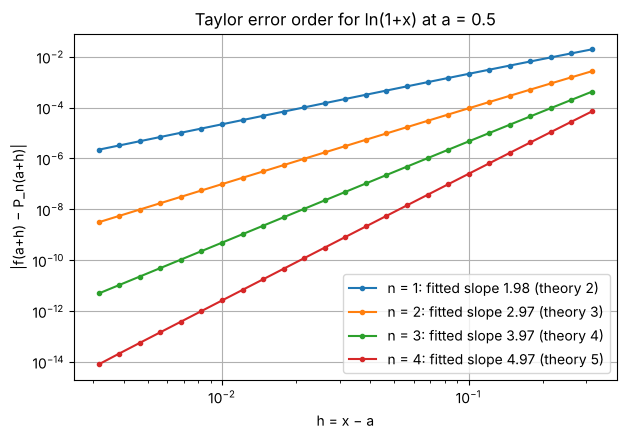

In [ ]:
expr = sp.log(1 + x)
a = 0.5
hs = np.logspace(-0.5, -2.5, 25)
f_true = np.log(1 + a + hs)

for n in [1, 2, 3, 4]:
    Pn = sp.lambdify(x, taylor_poly(expr, x, a, n), "numpy")
    err = np.abs(f_true - Pn(a + hs))
    slope = np.polyfit(np.log(hs), np.log(err), 1)[0]
    plt.loglog(hs, err, "o-", ms=3, label=f"n = {n}: fitted slope {slope:.2f} (theory {n + 1})")
plt.xlabel("h = x − a"); plt.ylabel("|f(a+h) − P_n(a+h)|")
plt.title("Taylor error order for ln(1+x) at a = 0.5")
plt.legend(); plt.show()

**Interpretation.** The fitted slopes are close to $2, 3, 4, 5$. So halving $h$ cuts the error of $P_n$ by about $2^{n+1}$, exactly as the remainder term $O(h^{n+1})$ predicts. This is the same reasoning behind the finite-difference slopes in §2.1. The central difference is accurate to $O(h^2)$ because, in the Taylor expansions of $f(a\pm h)$, the even-order terms cancel.

## 3.4 Taylor's theorem is local: radius of convergence

Taylor's theorem says $P_n$ is good *near* $a$. It does **not** promise that $P_n \to f$ everywhere as $n\to\infty$. For $\ln(1+x)$ at $a=0$,
$$P_n(x) = x - \frac{x^2}{2} + \frac{x^3}{3} - \cdots,$$
and this series converges only for $-1 < x \le 1$. Outside that interval, adding terms makes the approximation *worse*.

  n |  error at x = 0.5 |  error at x = 1.5
  2 |         3.047e-02 |         5.413e-01
  5 |         1.827e-03 |         8.368e-01
 10 |         3.046e-05 |         3.319e+00
 20 |         1.537e-08 |         9.774e+01
 30 |         1.012e-11 |         3.784e+03


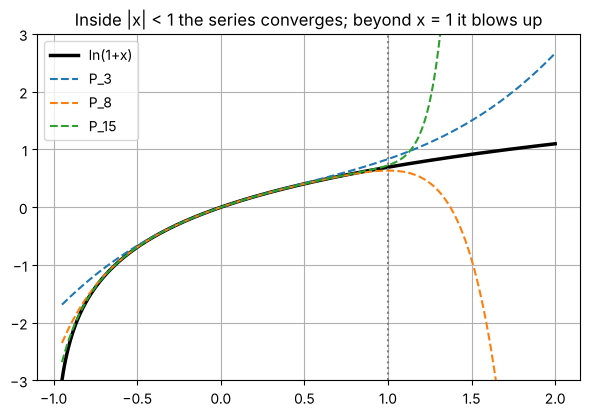

In [ ]:
expr = sp.log(1 + x)
print(f"{'n':>3} | {'error at x = 0.5':>17} | {'error at x = 1.5':>17}")
for n in [2, 5, 10, 20, 30]:
    Pn = sp.lambdify(x, taylor_poly(expr, x, 0, n), "numpy")
    print(f"{n:>3} | {abs(np.log(1.5) - Pn(0.5)):>17.3e} | {abs(np.log(2.5) - Pn(1.5)):>17.3e}")

t = np.linspace(-0.95, 2, 400)
plt.plot(t, np.log(1 + t), "k", lw=2.5, label="ln(1+x)")
for n in [3, 8, 15]:
    Pn = sp.lambdify(x, taylor_poly(expr, x, 0, n), "numpy")
    plt.plot(t, Pn(t), "--", label=f"P_{n}")
plt.axvline(1, c="gray", ls=":"); plt.ylim(-3, 3)
plt.legend(); plt.title("Inside |x| < 1 the series converges; beyond x = 1 it blows up"); plt.show()

**Interpretation.** At $x = 0.5$ the error falls toward $0$ as $n$ grows. At $x = 1.5$ it explodes. The remainder bound has the factor $|x-a|^{n+1}$, which grows with $n$ when $|x-a|>1$ and the derivatives do not shrink fast enough to compensate. Lesson: trust a Taylor approximation only near the expansion point. Optimization algorithms respect this with small step sizes and "trust regions."

## 3.5 Multivariable Taylor: the quadratic model

For $f:\mathbb{R}^d\to\mathbb{R}$ with continuous second derivatives,
$$f(\mathbf x + \boldsymbol\Delta) = f(\mathbf x) + \nabla f(\mathbf x)^T\boldsymbol\Delta + \tfrac12\,\boldsymbol\Delta^T\mathbf H_f(\mathbf x)\,\boldsymbol\Delta + o(\|\boldsymbol\Delta\|^2).$$
* The **first-order** (linear) model has error $O(\|\Delta\|^2)$. This is the model **gradient descent** uses.
* The **second-order** (quadratic) model has error $O(\|\Delta\|^3)$ when $f$ has three continuous derivatives. **Newton's method** uses this model, and its minimizer gives the Newton step $\boldsymbol\Delta = -\mathbf H^{-1}\nabla f$.

We test both error orders on our running function $f(x,y) = x^2 + 2y^2 + \sin(xy)$ at $\mathbf p_0 = (1, 0.5)$.

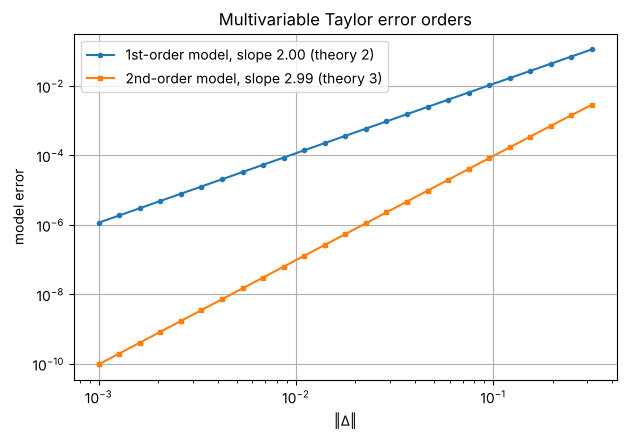

In [ ]:
g0 = np.array(grad_num(*p0), float)
H0 = np.array(H_num(*p0), float)
direction = np.array([0.6, -0.8])                 # a unit vector
ts = np.logspace(-0.5, -3, 25)

err1, err2 = [], []
for s in ts:
    d = s*direction
    true = f_num(*(p0 + d))
    lin  = f_num(*p0) + g0 @ d
    quad = lin + 0.5*d @ H0 @ d
    err1.append(abs(true - lin)); err2.append(abs(true - quad))

s1 = np.polyfit(np.log(ts), np.log(err1), 1)[0]
s2 = np.polyfit(np.log(ts), np.log(err2), 1)[0]
plt.loglog(ts, err1, "o-", ms=3, label=f"1st-order model, slope {s1:.2f} (theory 2)")
plt.loglog(ts, err2, "s-", ms=3, label=f"2nd-order model, slope {s2:.2f} (theory 3)")
plt.xlabel("‖Δ‖"); plt.ylabel("model error"); plt.legend()
plt.title("Multivariable Taylor error orders"); plt.show()

Hessian eigenvalues at p0: [1.661306 3.739412] (positive ⇒ quadratic model is a bowl)
Newton step lands at: [-0.086621 -0.120484]  f there = 0.046972  (f(p0) = 1.979426 )


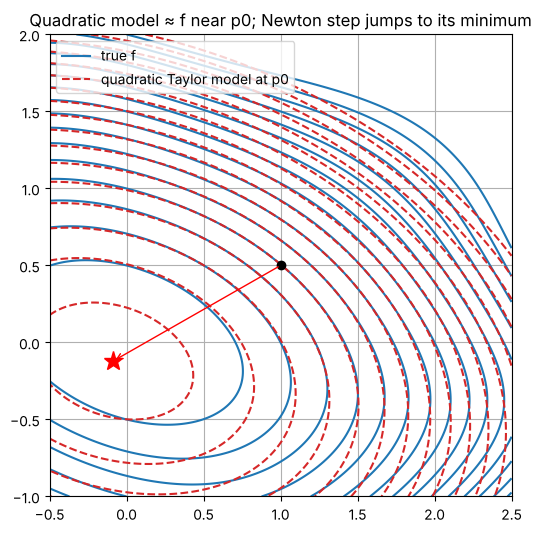

In [ ]:
# Compare the quadratic model with f on a neighbourhood of p0, and take one Newton step.
gx, gy = np.meshgrid(np.linspace(-0.5, 2.5, 200), np.linspace(-1, 2, 200))
dX, dY = gx - p0[0], gy - p0[1]
quad_model = (f_num(*p0) + g0[0]*dX + g0[1]*dY
              + 0.5*(H0[0, 0]*dX**2 + 2*H0[0, 1]*dX*dY + H0[1, 1]*dY**2))

newton = p0 - np.linalg.solve(H0, g0)
print("Hessian eigenvalues at p0:", np.linalg.eigvalsh(H0), "(positive ⇒ quadratic model is a bowl)")
print("Newton step lands at:", newton, " f there =", round(f_num(*newton), 6), " (f(p0) =", round(f_num(*p0), 6), ")")

levels = np.linspace(0, 8, 17)
plt.figure(figsize=(6.5, 6))
plt.contour(gx, gy, f_num(gx, gy), levels=levels, colors="C0")
plt.contour(gx, gy, quad_model, levels=levels, colors="C3", linestyles="--")
plt.plot(*p0, "ko"); plt.plot(*newton, "r*", ms=14)
plt.annotate("", xy=newton, xytext=p0, arrowprops=dict(arrowstyle="->", color="red"))
plt.plot([], [], "C0", label="true f"); plt.plot([], [], "C3--", label="quadratic Taylor model at p0")
plt.legend(loc="upper left"); plt.gca().set_aspect("equal")
plt.title("Quadratic model ≈ f near p0; Newton step jumps to its minimum"); plt.show()

**Interpretation.** The fitted slopes are about $2$ and $3$, confirming the multivariable error orders. In the contour plot, the dashed quadratic model matches the true level curves closely near $\mathbf p_0$ and drifts away farther out. That is Taylor's theorem being local again. A single Newton step, which jumps to the minimum of the quadratic model, lowers $f$ substantially. This shows how second-order Taylor expansions turn into an optimization algorithm, which leads into Section 3.3.